# Где открыть кофейню в Москве

**Учебный проект Яндекс Практикума**

Основатели фонда «Shut Up and Take My Money» хотят открыть доступную кофейню для встреч в духе Central Perk из «Друзей». Я сравнил заведения по районам Москвы, чтобы предложить округ для поиска помещения, цену капучино и режим работы для пилотной точки.

**Данные.** В учебной выгрузке 8 406 карточек московских заведений из Яндекс Карт и Яндекс Бизнеса за лето 2022 года. Цены в исследовании указаны в рублях этого периода.

**С чего начать.** Для проверки двух-трёх адресов я бы выбрал Северный округ. Летом 2022 года цену капучино указали 76 из 193 местных кофеен. Медиана составила 159 ₽ за чашку, в Центральном округе — 190 ₽. До аренды я бы сверил сегодняшние цены и посчитал поток у каждого входа.

**Содержание**

1. [Что попало в выборку](#section-1)
2. [Форматы, посадочные места и сети](#section-2)
3. [Округа, цены и карты](#section-3)
4. [Улицы и соседние заведения](#section-4)
5. [Кофейни, часы работы и цена капучино](#section-5)
6. [Рекомендация для пилота](#section-6)

<a id="section-1"></a>
## 1. Что попало в выборку

Одна строка в файле — одна карточка заведения. По ней можно узнать, где находится точка, как её описали в справочнике и какую оценку поставили пользователи. Здесь нет числа визитов, отзывов или заказов. Например, сеть с большим числом карточек широко представлена в городе, а её выручка остаётся неизвестной.

In [1]:
from pathlib import Path
import re
import pandas as pd
from IPython.display import display

folders = (Path("."), Path("data"), Path("/datasets"))
csv_path = next((folder / "moscow_places.csv" for folder in folders
                 if (folder / "moscow_places.csv").is_file()), None)
if csv_path is None:
    raise FileNotFoundError("Положите moscow_places.csv рядом с ноутбуком.")
raw = pd.read_csv(csv_path)
print(f"В файле {len(raw):,} карточек и {raw.shape[1]} столбцов.".replace(",", " "))
display(raw[["name", "category", "address", "hours", "rating"]].head(3))

В файле 8 406 карточек и 14 столбцов.


,name,category,address,hours,rating
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1","ежедневно, 10:00–22:00",5.0
1,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1","ежедневно, 10:00–22:00",4.5
2,Хазри,кафе,"Москва, Клязьминская улица, 15","пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6


In [2]:
descriptions = {
    "name": "Название точки", "category": "Формат заведения",
    "address": "Адрес", "district": "Административный округ Москвы",
    "hours": "Дни и часы работы", "lat": "Широта", "lng": "Долгота",
    "rating": "Оценка в Яндекс Картах, до 5 баллов",
    "price": "Словесная ценовая категория",
    "avg_bill": "Как в карточке описана цена заказа или отдельной позиции",
    "middle_avg_bill": "Середина диапазона среднего чека или единственная цена, ₽",
    "middle_coffee_cup": "Середина диапазона цены капучино или единственная цена, ₽",
    "chain": "Признак сети (1 — сетевая точка, 0 — самостоятельная)",
    "seats": "Количество посадочных мест",
}
fields = pd.DataFrame({
    "Что означает": pd.Series(descriptions),
    "Тип после чтения": raw.dtypes.astype(str),
    "Пропуски": raw.isna().sum(),
    "Доля пропусков, %": raw.isna().mean().mul(100).round(1),
}).reindex(raw.columns)
display(fields)

full_duplicates = raw.duplicated().sum()
df = raw.drop_duplicates().copy()
df["name_key"] = (df["name"].astype("string").str.normalize("NFKC")
                  .str.casefold().str.split().str.join(" "))
address_key = (df["address"].astype("string").str.normalize("NFKC")
               .str.casefold().str.split().str.join(" "))
normalized_keys = df.assign(address_key=address_key)[["name_key", "address_key"]]
same_location = normalized_keys.duplicated()
print(f"Полные дубли: {full_duplicates}. Совпадения по названию и адресу "
      f"после нормализации регистра и пробелов: {same_location.sum()}.")
display(df.loc[normalized_keys.duplicated(keep=False),
               ["name", "address", "category", "chain", "lat", "lng"]].sort_values("address"))

assert df["chain"].isin([0, 1]).all() and df["rating"].between(0, 5).all()
assert df["lat"].between(-90, 90).all() and df["lng"].between(-180, 180).all()

,Что означает,Тип после чтения,Пропуски,"Доля пропусков, %"
name,Название точки,str,0,0.0
category,Формат заведения,str,0,0.0
address,Адрес,str,0,0.0
district,Административный округ Москвы,str,0,0.0
hours,Дни и часы работы,str,536,6.4
lat,Широта,float64,0,0.0
lng,Долгота,float64,0,0.0
rating,"Оценка в Яндекс Картах, до 5 баллов",float64,0,0.0
price,Словесная ценовая категория,str,5091,60.6
avg_bill,Как в карточке описана цена заказа или отдельн...,str,4590,54.6


Полные дубли: 0. Совпадения по названию и адресу после нормализации регистра и пробелов: 4.


,name,address,category,chain,lat,lng
1430,More poke,"Москва, Волоколамское шоссе, 11, стр. 2",ресторан,0,55.806307,37.497566
1511,More Poke,"Москва, Волоколамское шоссе, 11, стр. 2",ресторан,1,55.806307,37.497566
3091,Хлеб да Выпечка,"Москва, Ярцевская улица, 19",булочная,1,55.738886,37.411648
3109,Хлеб да выпечка,"Москва, Ярцевская улица, 19",кафе,0,55.738449,37.410937
189,Кафе,"Москва, парк Ангарские Пруды",кафе,0,55.880327,37.530786
215,Кафе,"Москва, парк Ангарские пруды",кафе,0,55.881438,37.531848
2211,Раковарня Клешни и Хвосты,"Москва, проспект Мира, 118",ресторан,0,55.810553,37.638161
2420,Раковарня Клешни и хвосты,"Москва, проспект Мира, 118","бар,паб",1,55.810677,37.638379


Полных дублей нет. После приведения названий и адресов к одному регистру совпали четыре пары. У двух кафе в парке Ангарские пруды разные координаты. У More Poke совпали координаты, но расходятся расписание и признак сети. Ещё у двух пар различаются координаты и категория. Я сохранил все карточки. Если бы каждую пару посчитали одной точкой, итог уменьшился бы на четыре заведения из 8 406.

У всех точек известны категория, округ, координаты и рейтинг. Пропусков больше всего в сведениях о ценах. В одной карточке могли указать средний чек, в другой — цену капучино или бокала пива. Даже заполненная строка с ценой не всегда даёт сведения для обеих числовых колонок. Для цен и вместимости я оставляю пропуски и показываю, на скольких карточках основан результат.

Цена, равная нулю, один раз встречается в поле среднего чека. В расчёт стоимости заказа она не входит. Ноль посадочных мест возможен у точки навынос. Такие записи остаются в выборке, а вместимость залов ниже сравнивается среди заведений, где указано хотя бы одно место.

In [3]:
street_type = re.compile(
    r"\b(?:улица|проспект|шоссе|проезд|переулок|набережная|бульвар|площадь|аллея|"
    r"тупик|просек|просека|линия|дорога|спуск|тоннель|мост|кольцо|МКАД)\b", re.I)
street_aliases = {
    "ул. профсоюзная": "Профсоюзная улица", "ул. ярославская": "Ярославская улица",
    "пр-т комсомольский": "Комсомольский проспект", "улица крылатская": "Крылатская улица",
}

def extract_street(address):
    parts = [part.strip() for part in address.split(",")]
    for i, part in enumerate(parts[1:], start=1):
        if part.casefold() in street_aliases:
            return street_aliases[part.casefold()]
        # Название района «Проспект Вернадского» и название парка могут содержать тип улицы.
        if re.search(r"\b(?:район|округ|территория)\b|^парк\b", part, re.I):
            continue
        if street_type.search(part):
            if part == "Главная аллея" and i > 1:
                return f"{part} ({parts[i - 1]})"
            return part
    return pd.NA

df["street"] = df["address"].map(extract_street).astype("string")
normalized_hours = (df["hours"].astype("string").str.casefold()
                    .str.replace(r"\s+", " ", regex=True).str.strip())
df["hours_known"] = normalized_hours.notna() & normalized_hours.ne("").fillna(False)
df["is_24_7"] = normalized_hours.eq("ежедневно, круглосуточно").fillna(False).astype(bool)

print(f"Определена улица: {df['street'].notna().sum()} из {len(df)}.")
print(f"Найдено разных названий улиц: {df['street'].nunique()}.")
print(f"Известно расписание: {df['hours_known'].sum()}. "
      f"Подтверждено 24/7: {df['is_24_7'].sum()}.")

Определена улица: 8287 из 8406.
Найдено разных названий улиц: 1399.
Известно расписание: 7870. Подтверждено 24/7: 730.


Для улицы я проверил части адреса после названия города. У некоторых точек указан только парк, микрорайон или квартал. Такие точки по-прежнему видны на карте и участвуют в итогах по округу. К конкретной улице их привязать нельзя. Одноимённые Главные аллеи в разных парках учитываются отдельно.

Круглосуточным считаю заведение с записью «ежедневно, круглосуточно». Иногда точка работает всю ночь только по субботам. Признак 24/7 у неё будет равен `False`. Для карточек без расписания сохраняю отдельный признак `hours_known`, чтобы отличить неизвестный режим от подтверждённого.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

<a id="section-2"></a>
## 2. Из каких заведений складывается рынок

Сначала сравню число точек. Вместимость посчитаю отдельно среди заведений с известной положительной посадкой. Так точки с нулём мест и пустые карточки не будут определять размер зала.

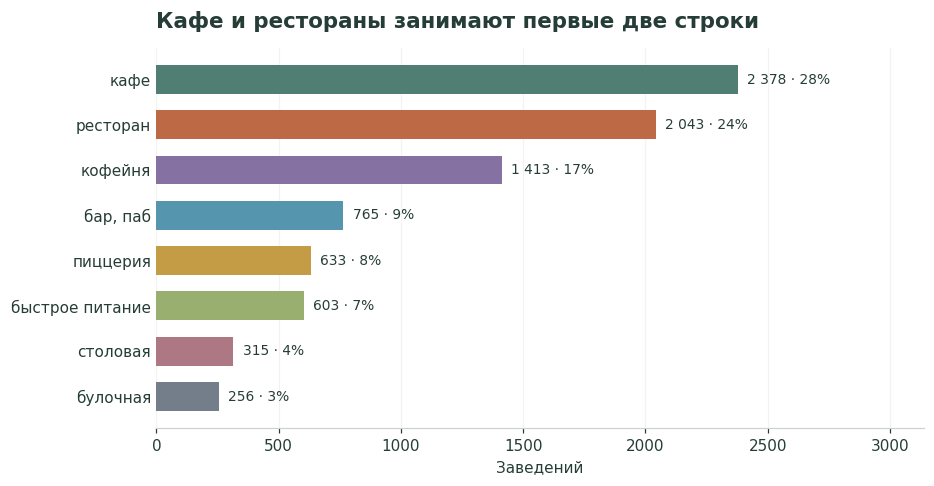

In [5]:
ink, green, muted, rust = '#263d37', '#267363', '#899b93', '#a34c31'
plt.rcParams.update({'figure.figsize': (9, 4.5), 'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'axes.edgecolor': '#cad3cb',
                     'axes.labelcolor': ink, 'xtick.color': ink, 'ytick.color': ink,
                     'text.color': ink, 'axes.titlelocation': 'left', 'axes.titlepad': 13,
                     'axes.titlesize': 14, 'axes.titleweight': 'bold',
                     'savefig.bbox': 'tight', 'figure.facecolor': 'white'})
format_colors = {'кафе': '#507e73', 'ресторан': '#bd6946', 'кофейня': '#8671a3',
                 'бар,паб': '#5695ae', 'пиццерия': '#c49c46', 'быстрое питание': '#98af6f',
                 'столовая': '#ad7783', 'булочная': '#737e8a'}
def pretty(category):
    return 'бар, паб' if category == 'бар,паб' else category

def bars(series, title, xlabel, colors, labels=None):
    fig, ax = plt.subplots(figsize=(8.6, max(2.6, 0.39 * len(series) + 1.4)))
    y = np.arange(len(series))
    rects = ax.barh(y, series, color=colors, height=.64)
    ax.set_yticks(y, [pretty(str(name)) for name in series.index])
    ax.invert_yaxis()
    ax.bar_label(rects, labels=labels, padding=6, fontsize=9)
    ax.set(xlim=(0, series.max() * 1.32), xlabel=xlabel, title=title)
    ax.tick_params(axis='y', length=0)
    ax.grid(axis='x', alpha=.14)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()

counts = df['category'].value_counts()
bars(counts, 'Кафе и рестораны занимают первые две строки', 'Заведений',
     [format_colors[c] for c in counts.index],
     [f'{n:,} · {n / len(df):.0%}'.replace(',', ' ') for n in counts])

Из 8 406 заведений 2 378 относятся к кафе и 2 043 к ресторанам. Вместе это 52,6% выборки. Кофейни идут третьими — 1 413 точек. Дальше буду рассматривать кофейни как отдельную категорию, даже если в ресторанах и пекарнях тоже продают кофе.

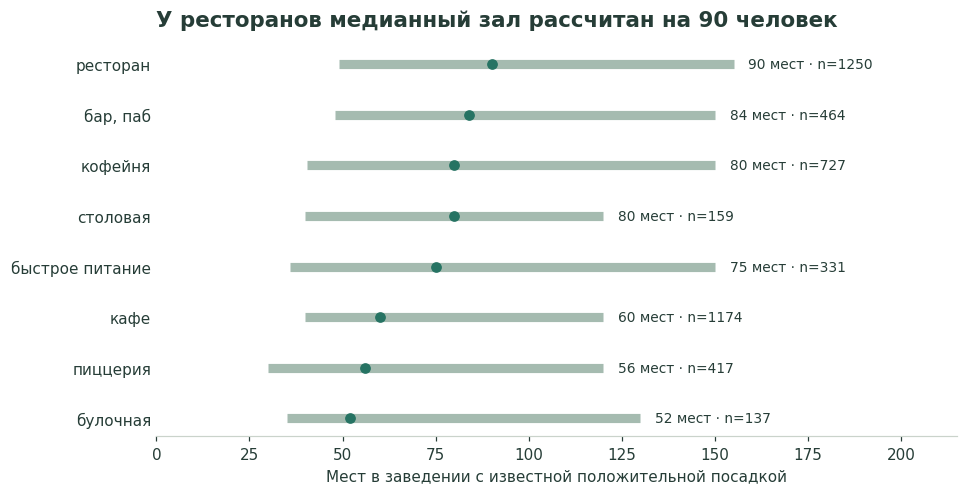

In [6]:
capacity = (df.assign(positive_seats=df['seats'].where(df['seats'].gt(0)))
            .groupby('category')['positive_seats']
            .agg(n='count', q1=lambda s: s.quantile(.25), median='median', q3=lambda s: s.quantile(.75))
            .sort_values('median', ascending=False))
fig, ax = plt.subplots(figsize=(8.9, 4.6))
y = np.arange(len(capacity))
ax.hlines(y, capacity.q1, capacity.q3, color='#a5bbb0', linewidth=6)
ax.scatter(capacity['median'], y, color=green, zorder=3)
ax.set_yticks(y, [pretty(c) for c in capacity.index])
for i, (_, row) in enumerate(capacity.iterrows()):
    ax.text(row.q3 + 4, i, f"{row['median']:.0f} мест · n={row.n:.0f}", va='center', fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(0, 215), xlabel='Мест в заведении с известной положительной посадкой',
       title='У ресторанов медианный зал рассчитан на 90 человек')
ax.tick_params(axis='y', length=0)
fig.tight_layout()
plt.show()

Точка показывает медиану, отрезок — среднюю половину значений. У булочных медиана 52 места, у пиццерий 56, у ресторанов 90. Интервалы заметно перекрываются. Среди 727 кофеен с положительным числом мест медиана равна 80. Проверю ещё одну деталь перед тем, как использовать это число для выбора помещения.

In [7]:
seats_by_address = (df.loc[df['seats'].gt(0)].groupby('address')['seats']
                    .agg(Карточек='size', Вариантов='nunique').query('Карточек > 1'))
print(f'Адресов с несколькими карточками и положительной посадкой: {len(seats_by_address)}. '
      f'Из них одинаковое число мест во всех таких карточках: {seats_by_address["Вариантов"].eq(1).sum()}.')

Адресов с несколькими карточками и положительной посадкой: 868. Из них одинаковое число мест во всех таких карточках: 868.


На всех 868 адресах с несколькими карточками, где указана положительная посадка, число мест у соседей совпадает. Возможно, справочник повторяет вместимость общего зала. Поэтому я бы не складывал посадочные места и не использовал медиану 80 как требование к метражу кофейни.

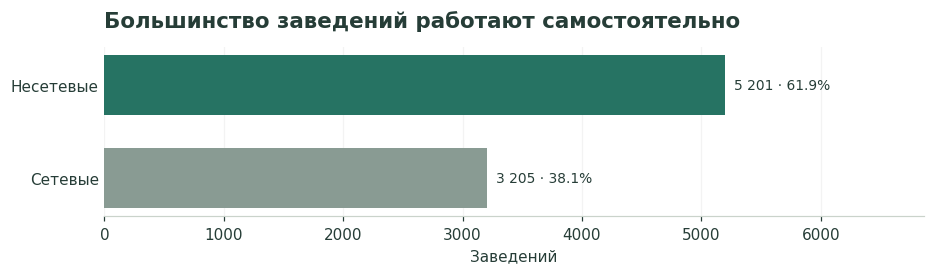

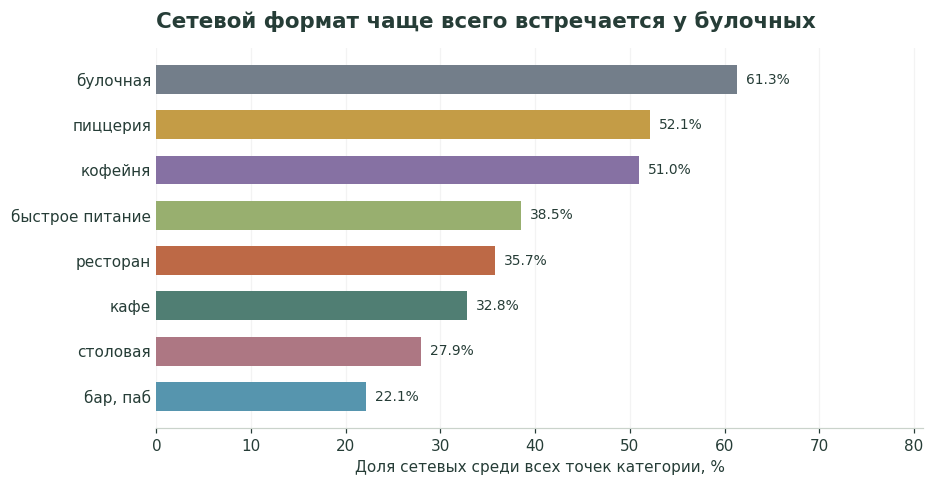

In [8]:
chain_counts = df['chain'].value_counts().reindex([0, 1])
chain_counts.index = ['Несетевые', 'Сетевые']
bars(chain_counts, 'Большинство заведений работают самостоятельно', 'Заведений',
     [green, muted], [f'{n:,} · {n / len(df):.1%}'.replace(',', ' ') for n in chain_counts])

chain_share = df.groupby('category')['chain'].mean().sort_values(ascending=False).mul(100)
bars(chain_share, 'Сетевой формат чаще всего встречается у булочных',
     'Доля сетевых среди всех точек категории, %', [format_colors[c] for c in chain_share.index],
     [f'{v:.1f}%' for v in chain_share])

В выборке 5 201 самостоятельное заведение и 3 205 сетевых. Сетевые точки составляют 38,1% рынка, но у булочных их 61,3%, у пиццерий 52,1%, у кофеен 51,0%. Будущая кофейня встретит и независимых соседей, и сети с узнаваемым меню.

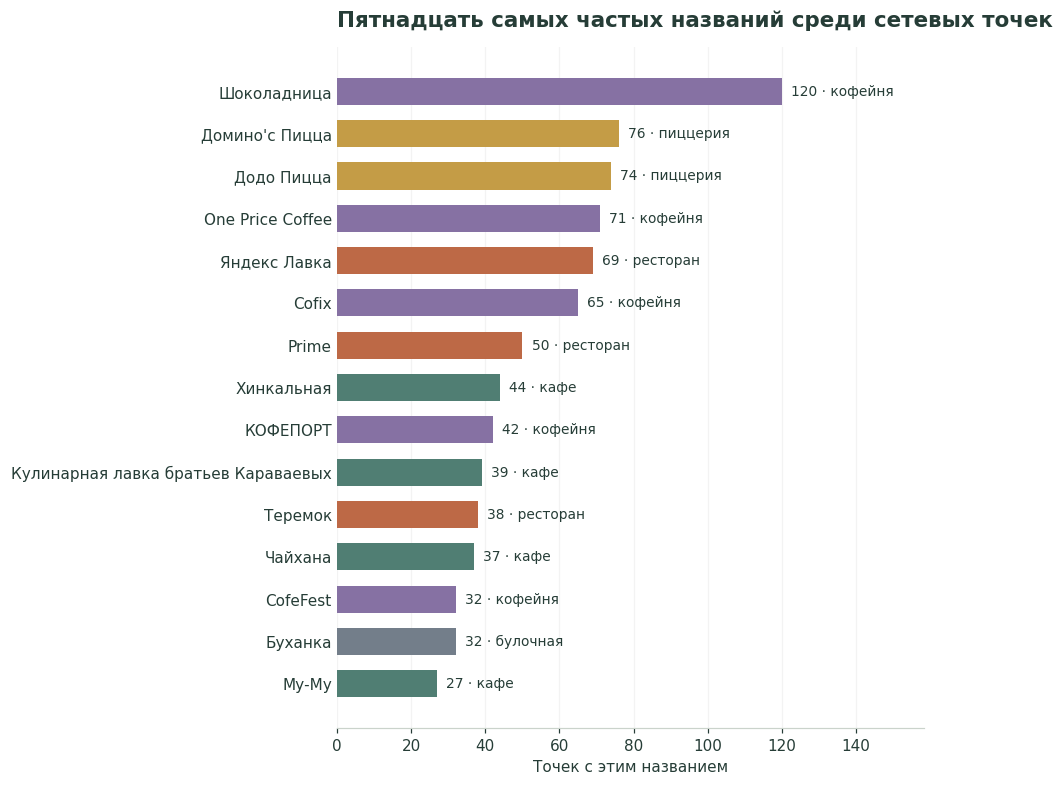

In [9]:
chains = df.loc[df['chain'].eq(1)].copy()
ranked = (chains.groupby('name_key').size().rename('n').reset_index()
          .sort_values(['n', 'name_key'], ascending=[False, True]).head(15).set_index('name_key'))
top_chain = ranked.copy()
top_chain['name'] = chains.groupby('name_key')['name'].agg(lambda s: s.value_counts().index[0])
top_chain['category'] = chains.groupby('name_key')['category'].agg(lambda s: s.value_counts().index[0])
series = top_chain.set_index('name')['n']
bars(series, 'Пятнадцать самых частых названий среди сетевых точек', 'Точек с этим названием',
     [format_colors[c] for c in top_chain['category']],
     [f'{n} · {pretty(c)}' for n, c in zip(series, top_chain['category'])])

У «Шоколадницы» 120 точек, из них 119 записаны как кофейни. Следом идут «Домино'с Пицца» и «Додо Пицца» с 76 и 74 пиццериями. Кофейни и пиццерии хорошо заметны в верхних строках. Справа у каждого названия указана его самая частая категория. «Хинкальная» и «Чайхана» — ещё и распространённые названия, поэтому по этой группировке нельзя установить единого владельца.

<a id="section-3"></a>
## 3. Чем различаются округа

В файле девять административных округов. Сравню в одном масштабе число заведений и состав предложения. Подпись в конце каждой полосы показывает общее число точек.

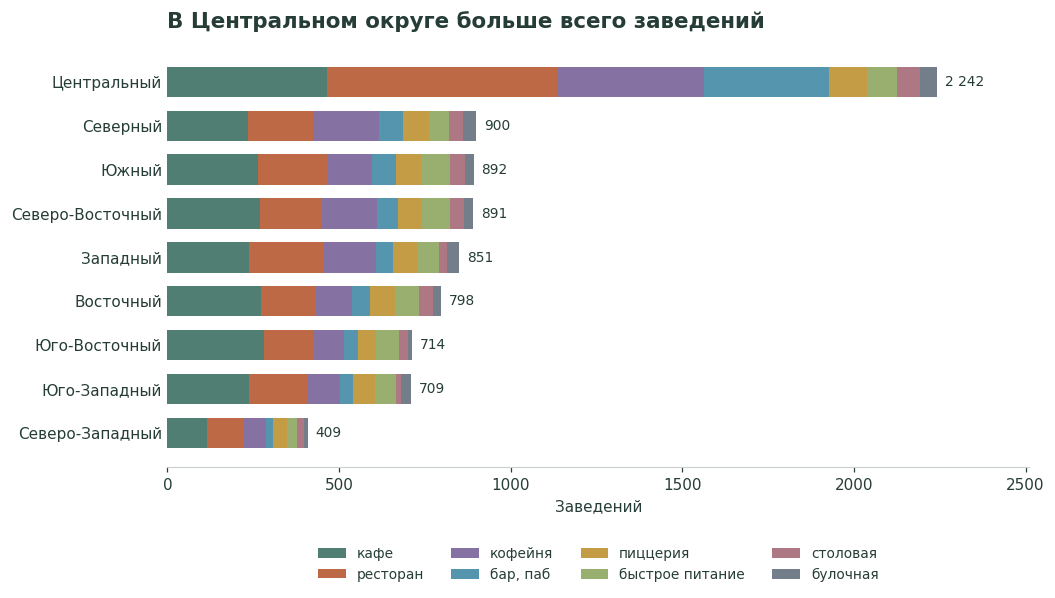

In [10]:
district_short = dict(zip(
    ['Центральный', 'Северный', 'Северо-Восточный', 'Восточный', 'Юго-Восточный',
     'Южный', 'Юго-Западный', 'Западный', 'Северо-Западный'],
    ['ЦАО', 'САО', 'СВАО', 'ВАО', 'ЮВАО', 'ЮАО', 'ЮЗАО', 'ЗАО', 'СЗАО']))
def short_district(name):
    return district_short[name.split(' административный')[0]]

def mix_chart(table, title):
    table = table.reindex(columns=counts.index, fill_value=0)
    total = table.sum(axis=1)
    fig, ax = plt.subplots(figsize=(9.7, .38 * len(table) + 2.2))
    y, left = np.arange(len(table)), np.zeros(len(table))
    for category, values in table.items():
        ax.barh(y, values, left=left, color=format_colors[category], label=pretty(category), height=.69)
        left += values.to_numpy()
    for i, n in enumerate(total):
        ax.annotate(f'{n:,}'.replace(',', ' '), (n, i), xytext=(5, 0), textcoords='offset points',
                    fontsize=9, va='center')
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set(xlim=(0, total.max() * 1.12), xlabel='Заведений', title=title)
    ax.tick_params(axis='y', length=0)
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.16), frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()

areas = pd.crosstab(df['district'], df['category'])
areas = areas.loc[areas.sum(axis=1).sort_values(ascending=False).index]
mix_chart(areas.rename(index=lambda x: x.replace(' административный округ', '')),
          'В Центральном округе больше всего заведений')

В ЦАО 2 242 точки, или 26,7% всей выборки. Северный, Южный и Северо-Восточный округа близки друг к другу — 900, 892 и 891 точка. В Северо-Западном их 409. Эти числа показывают, сколько соседей может встретиться в округе. Для сравнения насыщенности понадобились бы ещё площадь, население и дневной поток.

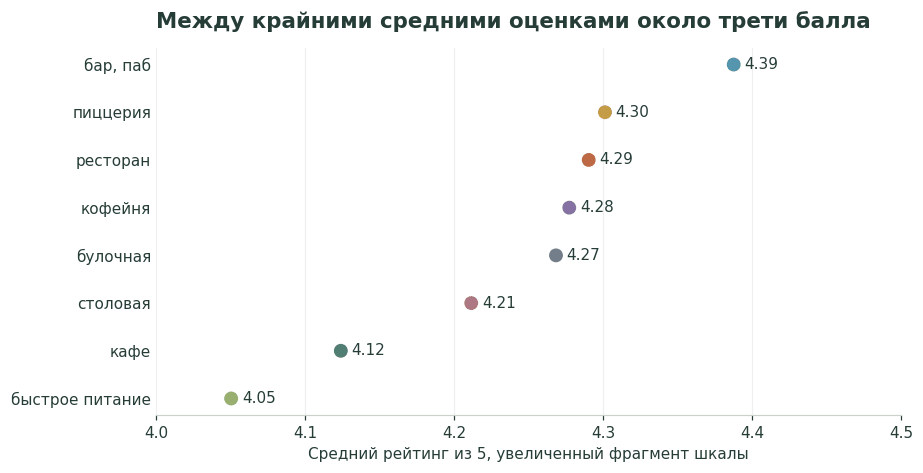

In [11]:
rating = df.groupby('category')['rating'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
y = np.arange(len(rating))
ax.scatter(rating, y, s=65, c=[format_colors[c] for c in rating.index])
for i, value in enumerate(rating):
    ax.annotate(f'{value:.2f}', (value, i), xytext=(7, 0), textcoords='offset points', va='center')
ax.set_yticks(y, [pretty(c) for c in rating.index])
ax.invert_yaxis()
ax.set(xlim=(4, 4.5), xlabel='Средний рейтинг из 5, увеличенный фрагмент шкалы',
       title='Между крайними средними оценками около трети балла')
ax.grid(axis='x', alpha=.2)
ax.tick_params(axis='y', length=0)
fig.tight_layout()
plt.show()

Самая высокая средняя оценка у баров и пабов (4,39), самая низкая у быстрого питания (4,05). Кофейни находятся ближе к верхней части списка (4,28). Для каждой категории это простое среднее оценок заведений. Сведения о числе голосов в карточках отсутствуют.

### Средний рейтинг и чек на карте

Для каждого округа посчитаю две величины. Первая — средняя оценка заведений: каждое заведение получает одинаковый вес, поскольку число отзывов в выгрузке не указано. Вторая — медиана опубликованных положительных средних чеков. Для неё отдельно покажу объём и покрытие выборки.

In [12]:
import json
from pathlib import Path
from urllib.request import urlopen
import matplotlib.patheffects as path_effects
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.path import Path as PlotPath
from matplotlib.patches import PathPatch

boundaries_name = "admin_level_geomap.geojson"
boundaries_url = "https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson"
boundaries_file = next((p for p in (Path(boundaries_name), Path("/datasets") / boundaries_name)
                        if p.is_file()), None)
if boundaries_file:
    boundaries = json.loads(boundaries_file.read_text(encoding="utf-8"))
else:
    with urlopen(boundaries_url, timeout=60) as response:
        boundaries = json.load(response)

by_district = df.assign(bill=df["middle_avg_bill"].where(df["middle_avg_bill"].gt(0))).groupby("district")
map_stats = by_district.agg(places=("name", "size"), rating=("rating", "mean"),
                            median_bill=("bill", "median"), bills=("bill", "count"),
                            label_x=("lng", "median"), label_y=("lat", "median"))
refs = {f["properties"]["name"]: f["properties"]["ref"] for f in boundaries["features"]}
assert set(map_stats.index) == set(refs), "Проверьте соответствие округов и границ"
map_stats["coverage"] = 100 * map_stats["bills"] / map_stats["places"]
map_table = map_stats[["places", "rating", "median_bill", "bills", "coverage"]].rename(index=refs)
map_table.columns = ["Заведений", "Средняя оценка", "Медиана чека, ₽", "Чеков", "Есть чек, %"]
display(map_table.sort_values("Медиана чека, ₽", ascending=False).style.format(
    {"Средняя оценка": "{:.2f}", "Медиана чека, ₽": "{:.0f}", "Есть чек, %": "{:.1f}"}))

,Заведений,Средняя оценка,"Медиана чека, ₽",Чеков,"Есть чек, %"
district,,,,,
ЗАО,851,4.18,1000,306,36.0
ЦАО,2242,4.38,1000,1059,47.2
СЗАО,409,4.21,700,157,38.4
САО,900,4.24,650,322,35.8
ЮЗАО,709,4.17,600,235,33.1
ВАО,798,4.17,575,260,32.6
СВАО,891,4.15,500,301,33.8
ЮАО,892,4.18,500,314,35.2
ЮВАО,714,4.10,450,194,27.2


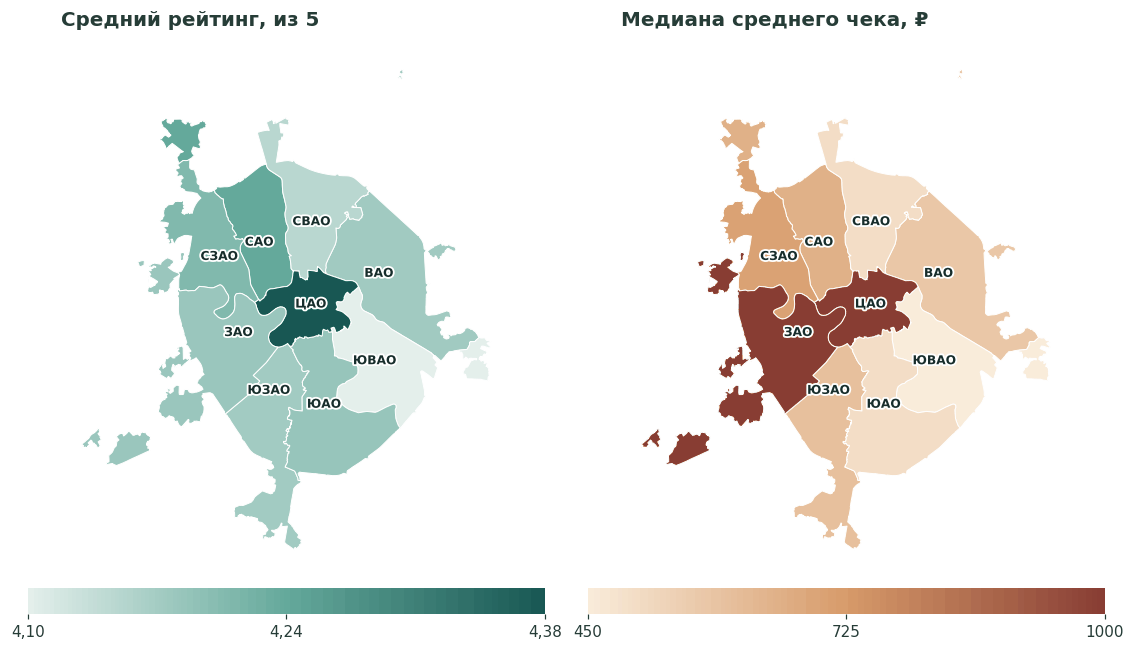

In [13]:
def district_map(ax, metric, title, colors, decimals):
    patches, values = [], []
    for feature in boundaries["features"]:
        name = feature["properties"]["name"]
        geom = feature["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for polygon in polygons:
            rings = [PlotPath(np.asarray(ring), closed=True) for ring in polygon]
            patches.append(PathPatch(PlotPath.make_compound_path(*rings)))
            values.append(map_stats.loc[name, metric])

    cmap = LinearSegmentedColormap.from_list(metric, colors)
    collection = PatchCollection(patches, cmap=cmap, edgecolor="white", linewidth=0.65,
                                 norm=Normalize(min(values), max(values)))
    collection.set_array(np.array(values))
    ax.add_collection(collection)
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.deg2rad(df["lat"].median())))
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=13)
    for district, row in map_stats.iterrows():
        tag = ax.text(row["label_x"], row["label_y"], refs[district], ha="center",
                      va="center", fontsize=8, weight="bold", color="#172d2c")
        tag.set_path_effects([path_effects.withStroke(linewidth=2.4, foreground="white")])
    bar = ax.figure.colorbar(collection, ax=ax, location="bottom", fraction=0.055, pad=0.025,
                             ticks=np.linspace(min(values), max(values), 3))
    bar.ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.{decimals}f}".replace(".", ","))
    bar.outline.set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 5.8), layout="constrained")
district_map(axes[0], "rating", "Средний рейтинг, из 5", ["#e4efeb", "#64a99b", "#185753"], 2)
district_map(axes[1], "median_bill", "Медиана среднего чека, ₽", ["#f9ecda", "#d79b6a", "#883d33"], 0)
plt.show()

Средняя оценка меняется от 4,10 в ЮВАО до 4,38 в ЦАО. Разрыв в 0,28 балла заметен на карте, но по среднему округа трудно судить об отдельном заведении.

Наибольшая медиана чека у ЦАО и ЗАО — по 1 000 ₽. В ЮВАО она составляет 450 ₽, в ЮАО и СВАО — по 500 ₽. Удаление от центра часто сопровождается более низким чеком, хотя пример западного округа показывает, что одного расстояния для объяснения цен мало. Доля карточек с ценой тоже различается: от 27% в ЮВАО до 47% в ЦАО.

### Где сосредоточены заведения

На карте я разбил территорию на одинаковые ячейки и посчитал заведения внутри каждой. Цвет показывает число карточек в ячейке. Логарифмическая шкала помогает рассмотреть и центр, и кварталы с редкими точками. Белые участки означают, что в соответствующих ячейках нет заведений из выборки.

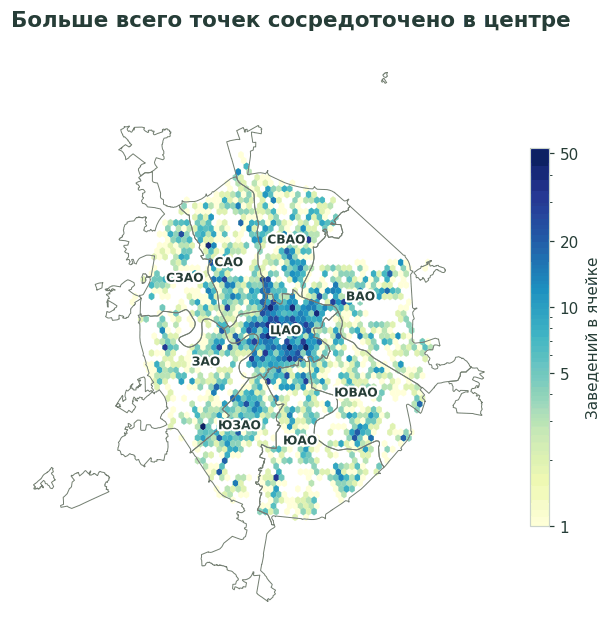

In [14]:
fig, ax = plt.subplots(figsize=(8.0, 5.7), layout='constrained')
for feature in boundaries['features']:
    geometry = feature['geometry']
    polygons = geometry['coordinates'] if geometry['type'] == 'MultiPolygon' else [geometry['coordinates']]
    for rings in polygons:
        for ring in rings:
            lon_ring, lat_ring = np.asarray(ring).T
            ax.plot(lon_ring, lat_ring, color='#747e72', linewidth=.65, zorder=2)

grid = ax.hexbin(df['lng'], df['lat'], gridsize=(55, 32), mincnt=1, bins='log',
                 cmap='YlGnBu', linewidths=.12)
assert int(grid.get_array().sum()) == len(df)
for name, row in map_stats.iterrows():
    label = ax.text(row.label_x, row.label_y, refs[name], fontsize=8, weight='bold',
                    va='center', ha='center', zorder=3)
    label.set_path_effects([path_effects.withStroke(linewidth=2.8, foreground='white')])
scale = fig.colorbar(grid, ax=ax, shrink=.65, pad=.03)
ticks = [t for t in (1, 5, 10, 20, 50, 100, 200) if t <= grid.get_array().max()]
scale.set_ticks(ticks, labels=[str(t) for t in ticks])
scale.set_label('Заведений в ячейке')
ax.set_aspect(1 / np.cos(np.deg2rad(df['lat'].median())))
ax.set_title('Больше всего точек сосредоточено в центре')
ax.set_axis_off()
plt.show()

In [15]:
import folium
from folium.plugins import FastMarkerCluster

# В Jupyter карта доступна по имени cluster_map после выполнения этой ячейки.
cluster_map = folium.Map(location=[df['lat'].median(), df['lng'].median()], zoom_start=10)
coords = df[['lat', 'lng']].to_numpy().tolist()
FastMarkerCluster(coords, options={'maxClusterRadius': 37, 'showCoverageOnHover': False}).add_to(cluster_map)
cluster_map.fit_bounds([[df['lat'].min(), df['lng'].min()], [df['lat'].max(), df['lng'].max()]])
print(f'В интерактивной карте {len(coords):,} заведений.'.replace(',', ' '))

В интерактивной карте 8 406 заведений.


Чтобы рассмотреть отдельный квартал при локальном запуске, выполните `display(cluster_map)` в новой ячейке Jupyter. Число на круге покажет, сколько заведений объединено в этой части карты.

Округа большие, и внутри них заведения могут быть на разном расстоянии от центра. Проверю ту же закономерность по координатам каждой точки.

In [16]:
center = df.loc[df['district'].str.startswith('Центральный'), ['lat', 'lng']].median()
lat, lng = np.radians(df['lat']), np.radians(df['lng'])
lat0, lng0 = np.radians(center)
a = np.sin((lat - lat0) / 2)**2 + np.cos(lat0) * np.cos(lat) * np.sin((lng - lng0) / 2)**2
km = 2 * 6371 * np.arcsin(np.sqrt(a.clip(0, 1)))
bands = pd.cut(km, [0, 3, 6, 10, 15, np.inf], labels=['до 3', '3–6', '6–10', '10–15', 'от 15'],
              right=False)
distance_table = (df.assign(band=bands, bill=df['middle_avg_bill'].where(df['middle_avg_bill'].gt(0)))
                  .groupby('band', observed=True)
                  .agg(Точек=('name', 'size'), Известных_чеков=('bill', 'count'), median_bill=('bill', 'median')))
distance_table.index.name = 'Расстояние, км'
display(distance_table.rename(columns={'Известных_чеков':'Известных чеков', 'median_bill':'Медианный чек, ₽'}))

,Точек,Известных чеков,"Медианный чек, ₽"
"Расстояние, км",,,
до 3,1312,651,1100.0
3–6,1716,738,750.0
6–10,1890,622,600.0
10–15,2533,835,600.0
от 15,955,302,500.0


За условный центр беру медианные широту и долготу заведений ЦАО. Расстояние считаю по прямой. В радиусе трёх километров медианный чек равен 1 100 ₽, с 6 до 15 км — 600 ₽, дальше 15 км — 500 ₽. Разница видна и без границ округов. Однако в центре другой набор заведений, а цены опубликованы лишь частью точек. По этим данным нельзя отделить влияние адреса от формата и аудитории.

<a id="section-4"></a>
## 4. На каких улицах больше всего соседей

Отберу 15 улиц по числу заведений и покажу, какие форматы там встречаются. Длинный проспект целиком может попасть в лидеры за счёт своей протяжённости. Для выбора помещения важнее конкуренты в нескольких минутах ходьбы от входа.

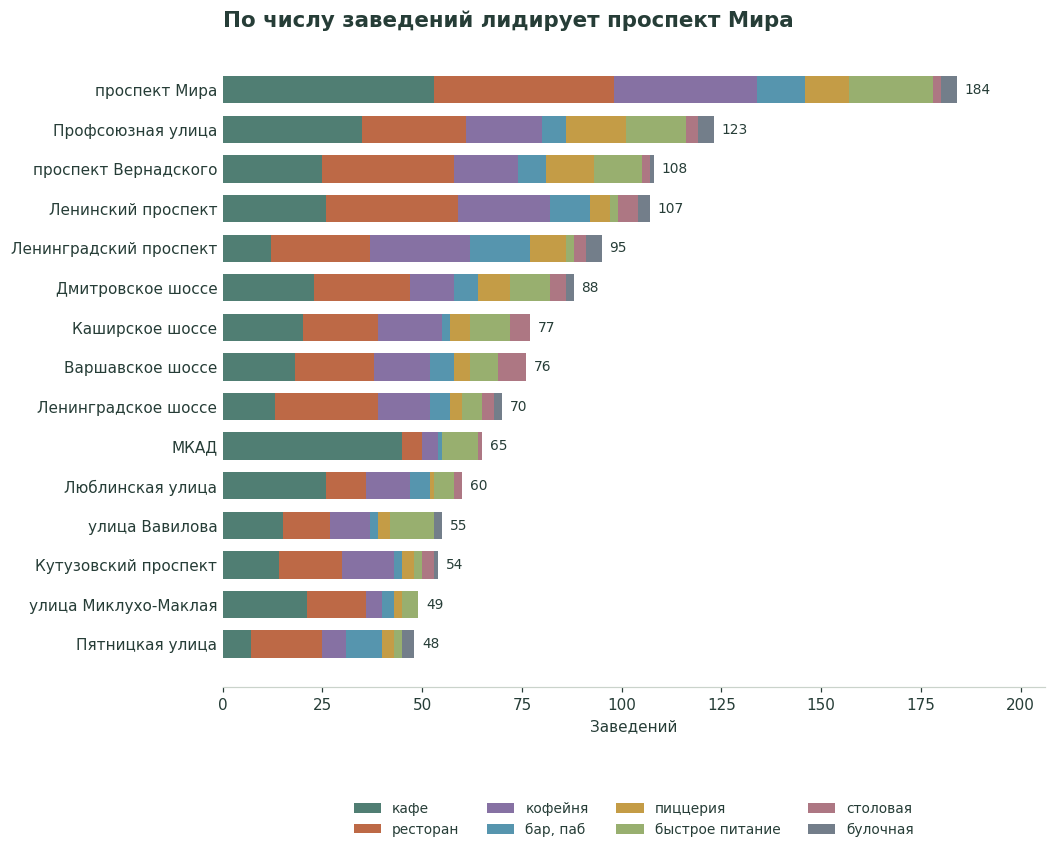

In [17]:
street_mix = pd.crosstab(df['street'], df['category'])
street_rank = (street_mix.sum(axis=1).rename('n').reset_index()
               .sort_values(['n', 'street'], ascending=[False, True]).set_index('street')['n'])
mix_chart(street_mix.loc[street_rank.head(15).index], 'По числу заведений лидирует проспект Мира')

На проспекте Мира 184 заведения, на Профсоюзной улице 123, на проспекте Вернадского 108. Улицы в рейтинге сравниваются по полному названию из адреса. Если его нет, исключаю карточку только из сравнения улиц.

In [18]:
singles = df[df['street'].isin(street_rank[street_rank.eq(1)].index)]
solo_categories = singles['category'].value_counts().reindex(counts.index, fill_value=0)
display(pd.DataFrame({'Точек': solo_categories,
                      'Доля среди одиночных точек, %': (solo_categories / len(singles) * 100).round(1),
                      'Доля среди всех точек, %': (counts / len(df) * 100).round(1)}))
print(f'Улиц с одной карточкой: {len(singles)} из {len(street_rank)}. '
      f'Несетевых заведений на них: {singles["chain"].eq(0).sum()}.')
display(singles.sort_values('street')[['street','name','category']].head(6)
        .rename(columns={'street':'Примеры улиц', 'name':'Заведение', 'category':'Категория'})
        .reset_index(drop=True))

,Точек,"Доля среди одиночных точек, %","Доля среди всех точек, %"
category,,,
кафе,146,34.0,28.3
ресторан,90,20.9,24.3
кофейня,76,17.7,16.8
"бар,паб",40,9.3,9.1
пиццерия,14,3.3,7.5
быстрое питание,20,4.7,7.2
столовая,36,8.4,3.7
булочная,8,1.9,3.0


Улиц с одной карточкой: 430 из 1399. Несетевых заведений на них: 312.


,Примеры улиц,Заведение,Категория
0,1-й Автозаводский проезд,Чайхана Азия,кафе
1,1-й Балтийский переулок,Хуан Хэ,ресторан
2,1-й Варшавский проезд,Колизей,кафе
3,1-й Вешняковский проезд,Deli by Shell,кафе
4,1-й Голутвинский переулок,Shelby,"бар,паб"
5,1-й Грайвороновский проезд,Домашняя кухня,"бар,паб"


На 430 из 1 399 распознанных улиц справочник показывает по одному заведению. Чаще всего это кафе (146), ресторан (90) или кофейня (76). Самостоятельных заведений здесь 312 из 430, или 72,6%, против 61,9% по всей выборке. Одна карточка на улице ещё не означает свободное место на рынке. Ближайший конкурент может находиться за углом.

### Что видно по рынку в целом

Больше половины заведений приходится на кафе и рестораны. В центре больше всего точек и один из самых высоких медианных чеков. При этом даже два округа с одинаковым медианным чеком могут заметно различаться по масштабу предложения. Для проекта с доступным кофе имеет смысл отдельно посмотреть на цену одной чашки и на соседние кофейни.

<a id="section-5"></a>
## 5. Сколько стоит чашка и где искать помещение

Оставлю только заведения категории «кофейня». Сначала сравню их число и оценки по округам, затем посмотрю, у скольких известен режим работы и цена капучино.

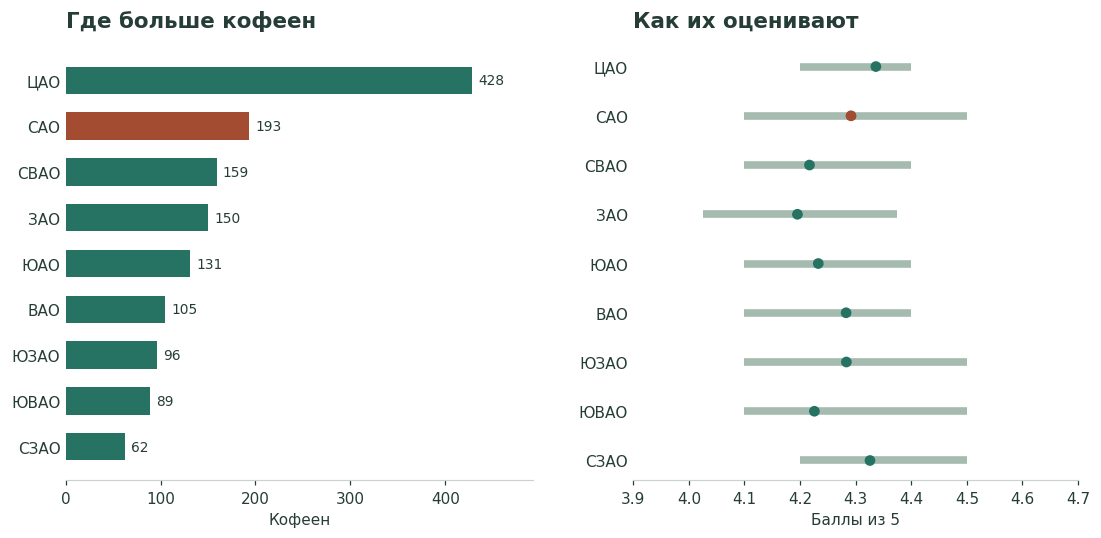

,Кофеен,% местного общепита,Средний рейтинг,Рейтинг Q1,Рейтинг Q3,Известен график,Из них 24/7
district,,,,,,,
ЦАО,428,19.09,4.34,4.20,4.40,426,26
САО,193,21.44,4.29,4.10,4.50,191,5
СВАО,159,17.85,4.22,4.10,4.40,157,3
ЗАО,150,17.63,4.20,4.03,4.38,148,9
ЮАО,131,14.69,4.23,4.10,4.40,130,1
ВАО,105,13.16,4.28,4.10,4.40,102,5
ЮЗАО,96,13.54,4.28,4.10,4.50,94,7
ЮВАО,89,12.46,4.23,4.10,4.50,88,1
СЗАО,62,15.16,4.33,4.20,4.50,62,2


In [19]:
coffee = df.loc[df['category'].eq('кофейня')].copy()
coffee['cup'] = coffee['middle_coffee_cup'].where(coffee['middle_coffee_cup'].gt(0))
coff = coffee.groupby('district').agg(
    n=('name', 'size'), score=('rating', 'mean'), rating_q1=('rating', lambda s: s.quantile(.25)),
    rating_q3=('rating', lambda s: s.quantile(.75)), hours=('hours_known', 'sum'),
    all_day=('is_24_7', 'sum'), prices=('cup', 'count'), cup=('cup', 'median'),
    q1=('cup', lambda s: s.quantile(.25)), q3=('cup', lambda s: s.quantile(.75))
).sort_values('n', ascending=False)
coff.index = coff.index.map(short_district)
local_share = coffee.groupby('district').size().div(df.groupby('district').size()).mul(100)
coff['local_share'] = local_share.rename(index=short_district)
fig, (ax, right) = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [1.05, 1]})
y = np.arange(len(coff))
colors = [rust if area == 'САО' else green for area in coff.index]
rects = ax.barh(y, coff.n, color=colors, height=.6)
ax.bar_label(rects, padding=4, fontsize=9)
ax.set(xlim=(0, coff.n.max() * 1.15), xlabel='Кофеен', title='Где больше кофеен')
right.hlines(y, coff.rating_q1, coff.rating_q3, color='#a5bbb0', linewidth=5)
right.scatter(coff.score, y, c=colors, zorder=3)
right.set(xlim=(3.9, 4.7), xlabel='Баллы из 5', title='Как их оценивают')
for axis in (ax, right):
    axis.set_yticks(y, coff.index)
    axis.invert_yaxis()
    axis.tick_params(axis='y', length=0)
fig.tight_layout(w_pad=3)
plt.show()

display(coff[['n','local_share','score','rating_q1','rating_q3','hours','all_day']].round(2)
        .rename(columns={'n':'Кофеен', 'local_share':'% местного общепита', 'score':'Средний рейтинг',
                         'rating_q1':'Рейтинг Q1','rating_q3':'Рейтинг Q3',
                         'hours':'Известен график','all_day':'Из них 24/7'}))

Из 1 413 кофеен 428 находятся в ЦАО (30,3%). В САО их 193, и кофейни составляют 21,4% всего общепита округа. Такой выбор даёт возможность найти близкие по формату точки и сравнить их вживую.

На правом графике точка — средняя оценка, полоса охватывает половину кофеен между первым и третьим квартилями. Средняя по городу равна 4,28, медиана 4,3. Самое высокое среднее у ЦАО (4,34), самое низкое у ЗАО (4,20). Разрыв в 0,14 балла мал по сравнению с разбросом оценок отдельных кофеен.

Круглосуточный режим подтверждён у 59 кофеен. Это 4,2% из 1 398 точек с известным графиком. Ещё у 15 график отсутствует. В САО круглосуточных пять из 191 с расписанием. Я бы начал с утренних и дневных часов, а вечерние встречи проверил отдельным пилотом. Ночную смену стоит рассматривать, когда есть данные о заказах и расходах на персонал.

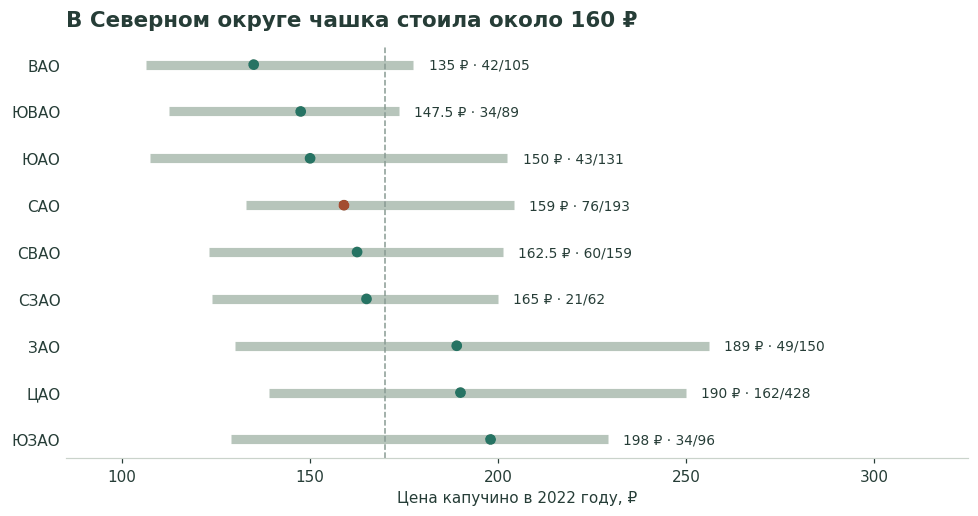

Цену указали 521 из 1413 кофеен (36.9%). Медиана по выборке — 170 ₽.


In [20]:
price_order = coff.sort_values('cup')
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(price_order))
ax.hlines(y, price_order.q1, price_order.q3, color='#b7c5bb', linewidth=6)
ax.scatter(price_order.cup, y, c=[rust if a == 'САО' else green for a in price_order.index], zorder=3)
for i, (_, row) in enumerate(price_order.iterrows()):
    ax.text(row.q3 + 4, i, f'{row.cup:g} ₽ · {row.prices:.0f}/{row.n:.0f}', va='center', fontsize=9)
ax.axvline(coffee['cup'].median(), ls='--', lw=1, color=muted)
ax.set_yticks(y, price_order.index)
ax.invert_yaxis()
ax.set(xlim=(85, 325), xlabel='Цена капучино в 2022 году, ₽', title='В Северном округе чашка стоила около 160 ₽')
ax.tick_params(axis='y', length=0)
fig.tight_layout()
plt.show()
print(f"Цену указали {coffee['cup'].count()} из {len(coffee)} кофеен "
      f"({coffee['cup'].notna().mean():.1%}). Медиана по выборке — {coffee['cup'].median():g} ₽.")

На графике точка — медиана, полоса — средняя половина цен, пунктир — медиана по городу. Справа указано, у скольких кофеен из общего числа была цена. Это цена чашки, указанная заведением, или середина заявленного диапазона. Реальные суммы покупок в файле отсутствуют.

В городе медиана равна 170 ₽ по 521 карточке с ценой из 1 413 (36,9%). В САО это 159 ₽ по 76 карточкам из 193, а средняя половина цен лежит примерно между 133 и 204 ₽. Для сравнения, в ВАО медиана 135 ₽, в ЦАО — 190 ₽. Ориентир около 160 ₽ в САО даёт гостю привычную для округа цену. Заполнение цен добровольное, поэтому предложения кофеен без цены могут отличаться.

<a id="section-6"></a>
## 6. С чего я бы начал

**Выбрал бы Северный округ для проверки двух-трёх адресов.** Здесь второй по величине выбор кофеен в датасете, а местная медианная цена чашки примерно на 31 ₽ ниже, чем в центре. Такой рынок подходит для проверки идеи доступного места встреч. Найденных данных достаточно, чтобы выбрать направление поиска. Окупится ли конкретное помещение, пока неизвестно.

**Проверил бы формат на месте.** У каждого адреса посчитал бы пешеходов утром, днём и вечером в будни и выходные. В соседних кофейнях посмотрел бы очереди, занятость столиков и актуальные цены. Для места, где друзья задерживаются надолго, важно понять, хватит ли выручки на час занятого столика.

**Сверил бы экономику до договора аренды.** Начальный ценовой ориентир по лету 2022 года — 160 ₽ за капучино. Для открытия сегодня его придётся пересчитать по свежим меню и себестоимости. Для каждого помещения я бы разделил постоянные расходы за день на маржу одного заказа и сравнил необходимое число заказов с результатом пилота. Заодно проверил бы, какая доля прохожих заходит за кофе.